# California Housing Price Regression

Predict the **median house value** of a California census block group from
socio-economic and geographic features, using the 1990 census data bundled with
scikit-learn (`fetch_california_housing`).

**Task:** regression — the target `MedHouseVal` is continuous and expressed in
units of **$100,000** (so `2.5` means about $250,000).

**Dataset at a glance**

| Property | Value |
| --- | --- |
| Rows | 20,640 |
| Features | 8 numeric |
| Target | `MedHouseVal` (0.15 – 5.00) |
| Missing values | none |

**Workflow**

1. Load the data.
2. Explore features, target and outliers.
3. Build a mean baseline and a linear regression model.
4. Analyse errors and residuals.
5. Compare decision tree, Ridge, polynomial Ridge and random forest models.
6. Evaluate the final random forest on the held-out test set and persist it.

## 1. Load the data

`fetch_california_housing(as_frame=True)` returns a `Bunch`; `.frame` is a
pandas `DataFrame` that still contains the target. The target is popped into
`y`, leaving the eight predictors in `df`.

In [5]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame
y = df.pop("MedHouseVal")


## 2. Explore the data

Before modelling, check the shape, dtypes, missing values and summary
statistics. This notebook uses main-memory pandas operations, so everything is
visible in the printed output.

Things to look for:

- No missing values and all features are numeric, so no imputation or encoding
  is required.
- `AveRooms`, `AveBedrms`, `Population` and `AveOccup` have long right tails
  (extreme values far above the median).
- `MedHouseVal` is capped at `5.00001`, which creates a ceiling effect in the
  target.

In [21]:
# Task: Inspect the data
print("Dataset shape:", df.shape)
print("Column names: ", df.columns)
print("A row from the dataset:\n", df.iloc[:1])
print("Missing values in each column:\n", df.isnull().sum())
print("Data types of each column:\n", df.dtypes)

Dataset shape: (20640, 8)
Column names:  Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='str')
A row from the dataset:
    MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127    1.02381       322.0  2.555556     37.88   

   Longitude  
0    -122.23  
Missing values in each column:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64
Data types of each column:
 MedInc        float64
HouseAge      float64
AveRooms      float64
AveBedrms     float64
Population    float64
AveOccup      float64
Latitude      float64
Longitude     float64
dtype: object


In [7]:
# Task: Inspect the target variable
print("Target variable shape:", y.shape)
print("Target variable statistics:\n", y.describe())
print("Missing values in target variable:", y.isnull().sum())

Target variable shape: (20640,)
Target variable statistics:
 count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64
Missing values in target variable: 0


In [14]:
print(df.describe().T)
print("HouseAge range:")
print(df["HouseAge"].min(), df["HouseAge"].max())

print("AveRooms range:")
print(df["AveRooms"].min(), df["AveRooms"].max())



              count         mean          std         min         25%  \
MedInc      20640.0     3.870671     1.899822    0.499900    2.563400   
HouseAge    20640.0    28.639486    12.585558    1.000000   18.000000   
AveRooms    20640.0     5.429000     2.474173    0.846154    4.440716   
AveBedrms   20640.0     1.096675     0.473911    0.333333    1.006079   
Population  20640.0  1425.476744  1132.462122    3.000000  787.000000   
AveOccup    20640.0     3.070655    10.386050    0.692308    2.429741   
Latitude    20640.0    35.631861     2.135952   32.540000   33.930000   
Longitude   20640.0  -119.569704     2.003532 -124.350000 -121.800000   

                    50%          75%           max  
MedInc         3.534800     4.743250     15.000100  
HouseAge      29.000000    37.000000     52.000000  
AveRooms       5.229129     6.052381    141.909091  
AveBedrms      1.048780     1.099526     34.066667  
Population  1166.000000  1725.000000  35682.000000  
AveOccup       2.818116 

### Correlation with the target

Pearson correlation gives a first, linear-only view of which features matter.
`MedInc` (median income) is by far the strongest positive signal; latitude and
longitude are negatively correlated because different coordinates point to
different parts of California. Correlation does not capture non-linear effects,
which is why tree-based models are tried later.

In [22]:
eda_df = df.copy()
eda_df["MedHouseVal"] = y

# Calculate correlations with the target
correlations = eda_df.corr(numeric_only=True)["MedHouseVal"]
print(correlations.sort_values(ascending=False))

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


### Feature relationships

Three scatter plots show the relationship between a feature and the target:

- `HouseAge` – almost no visible trend.
- `AveRooms` – a weak positive trend plus a few extreme outliers.
- `MedInc` – the clearest relationship; higher income generally means higher
  house value.

The plots motivate income-driven models and careful handling of outliers.

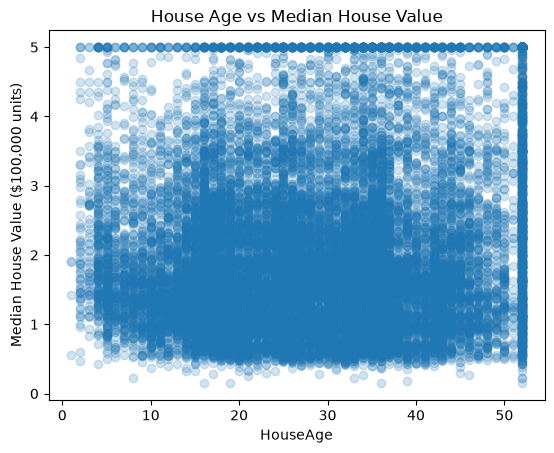

In [12]:
import matplotlib.pyplot as plt

plt.scatter(df["HouseAge"], y, alpha=0.2)
plt.xlabel("HouseAge")
plt.ylabel("Median House Value ($100,000 units)")
plt.title("House Age vs Median House Value")
plt.show()

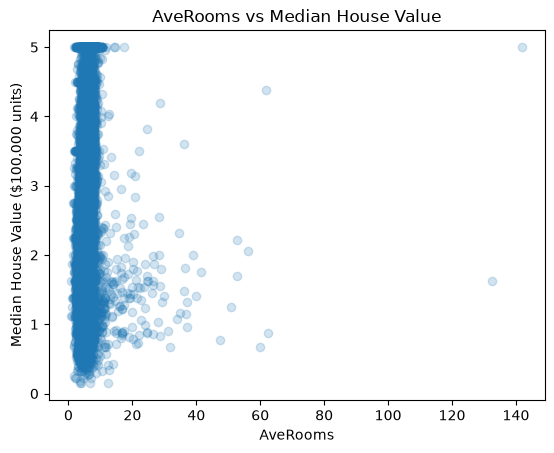

In [13]:
plt.scatter(df["AveRooms"], y, alpha=0.2)
plt.xlabel("AveRooms")
plt.ylabel("Median House Value ($100,000 units)")
plt.title("AveRooms vs Median House Value")
plt.show()

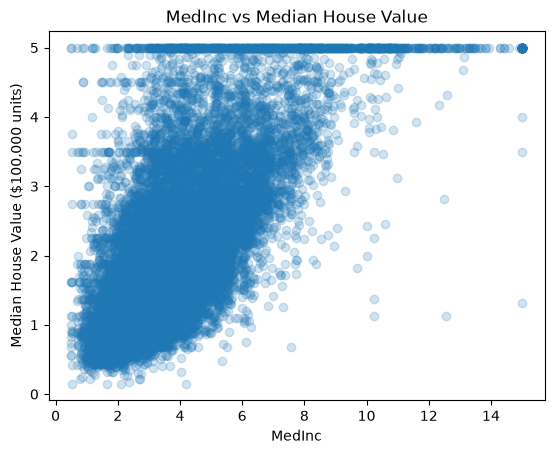

In [16]:
plt.scatter(df["MedInc"], y, alpha=0.2)
plt.xlabel("MedInc")
plt.ylabel("Median House Value ($100,000 units)")
plt.title("MedInc vs Median House Value")
plt.show()

### Investigating extreme values

The summary statistics show implausible values, e.g. `AveRooms` up to ~142 and
`AveOccup` up to ~1243. These usually come from very small census block groups
(few housing units or few occupants). Inspecting the largest `AveRooms` rows
shows whether they are genuine districts or artefacts. The models below keep
these rows; tree models are reasonably robust to them, while linear models can
be influenced by them.

In [17]:

# Inspect unusually high AveRooms values
columns_to_inspect = [
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "MedInc",
    "MedHouseVal"
]

eda_df = df.copy()
eda_df["MedHouseVal"] = y

print(
    eda_df.nlargest(10, "AveRooms")[columns_to_inspect]
)


         AveRooms  AveBedrms  Population  AveOccup  MedInc  MedHouseVal
1914   141.909091  25.636364        30.0  2.727273  1.8750      5.00001
1979   132.533333  34.066667        36.0  2.400000  4.6250      1.62500
12447   62.422222  14.111111        83.0  1.844444  1.6154      0.87500
1913    61.812500  11.000000       112.0  2.333333  4.0714      4.37500
11862   59.875000  15.312500        28.0  1.750000  2.6250      0.67500
1912    56.269231  10.153846        54.0  2.076923  4.9750      2.06300
9676    52.848214  11.410714       265.0  2.366071  3.2431      2.21400
11707   52.690476   8.857143        98.0  2.333333  1.1912      1.70000
2395    50.837838  10.270270        64.0  1.729730  3.8750      1.25000
1240    47.515152  11.181818        82.0  2.484848  3.1250      0.77500


## 3. Build a baseline model

A useful model must beat a trivial **mean baseline** that predicts the training
target mean for every validation example.

**Data split:** 60% train / 20% validation / 20% test. The validation set is
used for model selection; the test set is only touched at the end.

**Metrics**

| Metric | Meaning |
| --- | --- |
| MAE | Average absolute error in $100,000 units — easy to interpret |
| RMSE | Root mean squared error — penalises large errors more |
| R² | Share of target variance explained (0 = mean baseline, 1 = perfect) |

The cell fits `LinearRegression` on the training split and reports the baseline
and model scores on the validation split.

In [23]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import  mean_absolute_error, mean_squared_error, r2_score

# Split the dataset into training, validation, and test sets
X_train, X_tmp, y_train, y_temp = train_test_split(df, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_temp, test_size=0.5, random_state=42)


#mean 
baseline_value = y_train.mean()

# Step 2: Generate a constant prediction for every validation example
baseline_predictions = np.full(
    shape=len(y_val),
    fill_value=baseline_value
)

#model
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_val)

# Step 3: Evaluate the baseline
baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_r2 = r2_score(y_val, baseline_predictions)

print(f"Baseline MAE: {baseline_mae:.4f}")
print(f"Baseline R²: {baseline_r2:.4f}")

# Step 4: Evaluate Model
mse = mean_squared_error(y_val, predictions)
mae = mean_absolute_error(y_val, predictions)
r2  = r2_score(y_val, predictions)
    
print(f"Training examples: {len(X_train)}")
print(f"Validation examples: {len(X_val)}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"R^2 Score: {r2:.4f}")



Baseline MAE: 0.9039
Baseline R²: -0.0001
Training examples: 12384
Validation examples: 4128
Mean Squared Error: 0.5326
Mean Absolute Error: 0.5336
R^2 Score: 0.5920


## 4. Analyse errors

Aggregate metrics hide where the model fails. This section builds a validation
results table with the actual value, prediction, residual (actual − predicted)
and absolute error, then inspects the worst cases.

A large residual means a confident but wrong prediction; understanding whether
errors cluster around capped values, luxury districts or unusual block groups
is the first step towards improving the model.

In [45]:
results = pd.DataFrame({
    "actual": y_val,
    "predicted": predictions
})
results["residual"] = results['actual'] - results['predicted']
results["absolute_error"] = abs(results['residual'])
print(results.head())

print("\n\n\n",results.sort_values(by='absolute_error',ascending=False).head())

# inspecting high abs error
print("\n\n11912 Error report :\n")
print(df.loc[11912])
print("Actual:",y_val[11912])
print("Predictions",predictions[X_val.index.get_loc(11912)])


      actual  predicted  residual  absolute_error
5595   1.280   1.750787 -0.470787        0.470787
8046   1.866   2.203428 -0.337428        0.337428
3798   2.094   1.885899  0.208101        0.208101
6659   1.731   1.807061 -0.076061        0.076061
9567   0.750   1.129132 -0.379132        0.379132



         actual  predicted  residual  absolute_error
11912  1.12500   5.657977 -4.532977        4.532977
11862  0.67500   4.953414 -4.278414        4.278414
10574  5.00001   1.119156  3.880854        3.880854
12389  5.00001   1.317085  3.682925        3.682925
4548   0.67500   4.237192 -3.562192        3.562192


11912 Error report :

MedInc         12.538100
HouseAge       29.000000
AveRooms        6.888889
AveBedrms       1.222222
Population     50.000000
AveOccup        2.777778
Latitude       33.960000
Longitude    -117.440000
Name: 11912, dtype: float64
Actual: 1.125
Predictions 5.657977254995572


### Coefficients and residual distribution

For a linear model, coefficients describe the average change in the target for
a one-unit change in a feature, holding the others constant. `AveBedrms` and
`MedInc` have the largest magnitudes here. Resident population appears
unimportant because it is dominated by other size-related features.

The residual summary shows the average error (close to zero) and the spread of
errors; the worst residuals reach several hundred thousand dollars.

In [53]:
#Cofficient analysis
coefficients = pd.Series(model.coef_, index=df.columns)
print(coefficients.sort_values(ascending=False))

print(results["residual"].describe())

AveBedrms     0.820335
MedInc        0.449245
HouseAge      0.009505
Population   -0.000001
AveOccup     -0.003214
AveRooms     -0.128103
Latitude     -0.418426
Longitude    -0.433788
dtype: float64
count    4128.000000
mean        0.003763
std         0.729849
min        -4.532977
25%        -0.460411
50%        -0.123169
75%         0.323789
max         3.880854
Name: residual, dtype: float64


### Residual plot

Plotting residuals against actual values checks two assumptions: errors should
be centred on zero and have a roughly constant spread. A pattern or a funnel
shape indicates that a linear model is missing non-linear structure — which is
exactly what the tree-based models below can capture.

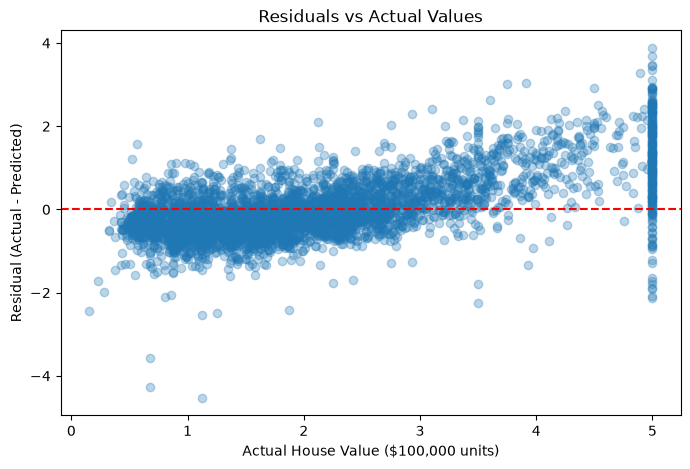

In [54]:
plt.figure(figsize=(8, 5))
plt.scatter(results["actual"], results["residual"], alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Actual House Value ($100,000 units)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Actual Values")
plt.show()

## 5. Try other models

Linear regression underfits this dataset. The following experiments test models
with increasing flexibility:

1. Decision tree (depth and leaf-size tuning).
2. Ridge regression (regularised linear model).
3. Polynomial features + Ridge (non-linear feature interactions).
4. Random forest (ensemble of trees) — selected as the final model.

Each candidate is compared on the same validation split using MAE and R².

### Decision tree

A decision tree splits the feature space into regions and predicts a constant
value per region. It handles non-linearity and feature interactions
automatically and needs no scaling. The first tree is limited to
`max_depth=10` to avoid memorising the training data.

In [55]:
from sklearn.tree import DecisionTreeRegressor
tree_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_val)

tree_mae = mean_absolute_error(y_val, tree_predictions)
tree_r2 = r2_score(y_val, tree_predictions)

print("Linear Regression MAE:", mean_absolute_error(y_val, predictions))
print("Decision Tree MAE:", tree_mae)

print("Linear Regression R²:", r2_score(y_val, predictions))
print("Decision Tree R²:", tree_r2)

Linear Regression MAE: 0.5336164161743364
Decision Tree MAE: 0.4388425150848387
Linear Regression R²: 0.5920099290350326
Decision Tree R²: 0.6622667614967848


### Tuning tree depth

A deeper tree fits the training data better but can overfit. Watch the gap
between `train_mae` and `val_mae`: as depth grows, training error approaches
zero while validation error stops improving or gets worse. Shallow trees
underfit, while unlimited-depth trees overfit sharply.

In [56]:
results_depth = []

for depth in [3, 5, 10, 15, 20, None]:
    tree = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    val_pred = tree.predict(X_val)

    results_depth.append({
        "max_depth": str(depth),
        "train_mae": mean_absolute_error(y_train, train_pred),
        "val_mae": mean_absolute_error(y_val, val_pred),
        "train_r2": r2_score(y_train, train_pred),
        "val_r2": r2_score(y_val, val_pred)
    })

depth_results = pd.DataFrame(results_depth)
print(depth_results.round(4))

  max_depth  train_mae  val_mae  train_r2  val_r2
0         3     0.5827   0.6049    0.5385  0.5013
1         5     0.5102   0.5336    0.6328  0.5891
2        10     0.3093   0.4388    0.8424  0.6623
3        15     0.1105   0.4533    0.9670  0.6070
4        20     0.0158   0.4649    0.9977  0.5935
5      None     0.0000   0.4708    1.0000  0.5813


### Tuning minimum samples per leaf

`min_samples_leaf` controls the minimum number of examples in a leaf and is a
second regularisation knob. Larger leaves produce smoother, less variance-prone
predictions; very large leaves underfit. The best combination so far uses
`max_depth=10` with a moderate leaf size.

In [57]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

leaf_results = []

for leaf_size in [1, 2, 5, 10, 20, 50]:
    tree = DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=leaf_size,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    val_pred = tree.predict(X_val)

    leaf_results.append({
        "min_samples_leaf": leaf_size,
        "train_mae": mean_absolute_error(y_train, train_pred),
        "val_mae": mean_absolute_error(y_val, val_pred)
    })

print(pd.DataFrame(leaf_results).round(4))

   min_samples_leaf  train_mae  val_mae
0                 1     0.3093   0.4388
1                 2     0.3173   0.4392
2                 5     0.3336   0.4392
3                10     0.3496   0.4289
4                20     0.3681   0.4330
5                50     0.4004   0.4506


### Decision tree evaluated on the test set

The tuned tree is refit on the training split and scored once on the test
split, giving an unbiased estimate of its performance. This is the first
test-set result in the notebook.

In [59]:
from sklearn.tree import DecisionTreeRegressor

final_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)

final_model.fit(X_train, y_train)

test_predictions = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print(f"Test MAE:  {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R²:   {test_r2:.4f}")

Test MAE:  0.4364
Test RMSE: 0.6441
Test R²:   0.6974


### Ridge regression

Ridge adds an L2 penalty on the coefficients. The features have very different
scales (income in tens of thousands, coordinates in degrees), so
`StandardScaler` is applied inside a pipeline. `alpha` controls the strength of
regularisation; on this dataset the validation scores are almost flat because
linear models cannot capture the dominant non-linearity.

In [60]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

for alpha in [0.1, 1.0, 10.0, 100.0]:
    ridge_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    ridge_model.fit(X_train, y_train)
    ridge_predictions = ridge_model.predict(X_val)

    print(
        f"Alpha: {alpha:5.1f} | "
        f"MAE: {mean_absolute_error(y_val, ridge_predictions):.4f} | "
        f"R²: {r2_score(y_val, ridge_predictions):.4f}"
    )

Alpha:   0.1 | MAE: 0.5336 | R²: 0.5920
Alpha:   1.0 | MAE: 0.5336 | R²: 0.5920
Alpha:  10.0 | MAE: 0.5336 | R²: 0.5921
Alpha: 100.0 | MAE: 0.5339 | R²: 0.5917


### Polynomial features + Ridge

`PolynomialFeatures(degree=2)` expands the eight inputs into linear terms,
squares and pairwise interactions (~44 features). Combined with scaling and
Ridge, this lets a linear model represent curved relationships. Degree 2 helps,
but the model still trails the tree ensembles because it cannot represent
sharp, local effects such as neighbourhood boundaries.

In [61]:
from sklearn.preprocessing import  PolynomialFeatures

poly_ridge = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Ridge(alpha=10.0)
)

poly_ridge.fit(X_train, y_train)

poly_predictions = poly_ridge.predict(X_val)

print("Polynomial Ridge MAE:",
      mean_absolute_error(y_val, poly_predictions))

print("Polynomial Ridge R²:",
      r2_score(y_val, poly_predictions))

Polynomial Ridge MAE: 0.5029867082997413
Polynomial Ridge R²: 0.6368270760639569


### Choosing the polynomial regularisation strength

A smaller `alpha` lets the expanded model fit more aggressively. Validation MAE
and R² improve at low `alpha` but degrade as regularisation becomes too strong;
this sweep picks a sensible value for comparison.

In [62]:
for alpha in [0.1, 1, 10, 100, 1000]:
    model = make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_val)

    print(
        f"Alpha={alpha:6} | "
        f"MAE={mean_absolute_error(y_val, pred):.4f} | "
        f"R²={r2_score(y_val, pred):.4f}"
    )

Alpha=   0.1 | MAE=0.4808 | R²=0.6512
Alpha=     1 | MAE=0.4907 | R²=0.6510
Alpha=    10 | MAE=0.5030 | R²=0.6368
Alpha=   100 | MAE=0.5162 | R²=0.6190
Alpha=  1000 | MAE=0.5333 | R²=0.5924


### Random forest

A random forest averages many decorrelated decision trees. Averaging reduces
the variance that made a single deep tree overfit, while still capturing
non-linearities and interactions. It also provides a useful by-product:
feature importances (not computed here, but available via
`forest.feature_importances_`).

In [63]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

forest.fit(X_train, y_train)

forest_predictions = forest.predict(X_val)

print("Random Forest MAE:",
      mean_absolute_error(y_val, forest_predictions))

print("Random Forest R²:",
      r2_score(y_val, forest_predictions))

Random Forest MAE: 0.3490005588642977
Random Forest R²: 0.7862707897092661


### Train vs validation scores

Comparing training and validation error shows how much the forest overfits. A
small gap means the model generalises; a large gap means it memorises the
training split. This check guides the hyperparameter search below.

In [64]:
forest_train_predictions = forest.predict(X_train)

print(
    "Train MAE:",
    mean_absolute_error(y_train, forest_train_predictions)
)

print(
    "Validation MAE:",
    mean_absolute_error(y_val, forest_predictions)
)

print(
    "Train R²:",
    r2_score(y_train, forest_train_predictions)
)

print(
    "Validation R²:",
    r2_score(y_val, forest_predictions)
)

Train MAE: 0.23056542483040515
Validation MAE: 0.3490005588642977
Train R²: 0.9029713030096325
Validation R²: 0.7862707897092661


### Random forest hyperparameter search

This small grid searches `max_depth` and `min_samples_leaf` while keeping
`n_estimators=100`. Results are sorted by validation MAE. Unlimited depth with
small leaves performs best, because averaging many trees controls variance
better than constraining a single tree.

In [65]:
from sklearn.ensemble import RandomForestRegressor

forest_results = []

for depth in [10, 15, 20, None]:
    for leaf_size in [2, 5, 10, 20]:
        model = RandomForestRegressor(
            n_estimators=100,
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)

        forest_results.append({
            "max_depth": str(depth),
            "min_samples_leaf": leaf_size,
            "train_mae": mean_absolute_error(y_train, train_pred),
            "val_mae": mean_absolute_error(y_val, val_pred),
            "val_r2": r2_score(y_val, val_pred)
        })

forest_results_df = pd.DataFrame(forest_results)

print(
    forest_results_df
    .sort_values("val_mae")
    .round(4)
    .to_string(index=False)
)

max_depth  min_samples_leaf  train_mae  val_mae  val_r2
     None                 2     0.1493   0.3406  0.7958
       20                 2     0.1515   0.3406  0.7958
       15                 2     0.1777   0.3440  0.7934
       20                 5     0.2230   0.3472  0.7873
     None                 5     0.2228   0.3473  0.7873
       15                 5     0.2306   0.3490  0.7863
     None                10     0.2790   0.3605  0.7754
       20                10     0.2790   0.3605  0.7753
       15                10     0.2804   0.3609  0.7751
       10                 5     0.2984   0.3739  0.7676
       10                 2     0.2873   0.3749  0.7689
       10                10     0.3162   0.3783  0.7623
       20                20     0.3271   0.3809  0.7570
     None                20     0.3271   0.3809  0.7570
       15                20     0.3271   0.3809  0.7570
       10                20     0.3419   0.3899  0.7506


### Final random forest

The best configuration (`max_depth=None`, `min_samples_leaf=2`) is refit on the
training split and evaluated once on the untouched test split. The final scores
confirm that the forest generalises better than the single tree, linear and
polynomial models.

In [66]:

final_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_forest.fit(X_train, y_train)

test_predictions = final_forest.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, test_predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_predictions)))
print("Test R²:", r2_score(y_test, test_predictions))

Test MAE: 0.3432348353320523
Test RMSE: 0.5241391548051025
Test R²: 0.7996377393224053


## 6. Save and reuse the model

The fitted forest is persisted with `joblib`, then loaded back and used to
predict a single unseen row. Predictions are in units of $100,000, so the
printed value is multiplied by 100,000 to express it in dollars.

This pattern — fit, dump, load, predict — is how the model would be served from
a script, API or dashboard.

In [67]:
import joblib

joblib.dump(final_forest, "california_housing_rf.joblib")

loaded_model = joblib.load("california_housing_rf.joblib")

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]

print("Predicted value:", prediction)
print("Predicted value in dollars:", prediction * 100_000)

Predicted value: 1.141221404761905
Predicted value in dollars: 114122.14047619049


## 7. Summary and next steps

**Results on the validation split**

| Model | MAE | R² |
| --- | --- | --- |
| Mean baseline | 0.9039 | -0.0001 |
| Linear regression | 0.5336 | 0.5920 |
| Decision tree (`max_depth=10`) | 0.4388 | 0.6623 |
| Polynomial Ridge (`degree=2`, `alpha=0.1`) | 0.4808 | 0.6512 |
| Random forest (`max_depth=None`, `min_samples_leaf=2`) | 0.3406 | 0.7958 |

**Final test scores (random forest):** MAE 0.343, RMSE 0.524, R² 0.800.

**What the notebook demonstrates**

- A complete regression workflow: EDA, baseline, model comparison, tuning,
  error analysis and final evaluation.
- Why non-linear, ensemble models outperform linear models on this dataset.
- How to persist and reload a trained model with `joblib`.

**Possible next steps**

- Add feature engineering (distance to coast/cities, income ratios) and target
  transformations.
- Use `RandomForestRegressor.feature_importances_` or permutation importance
  for interpretability.
- Try gradient boosting (`HistGradientBoostingRegressor`, XGBoost, LightGBM)
  and cross-validated hyperparameter search.
- Treat the capped target (`MedHouseVal == 5.00001`) explicitly, e.g. with a
  two-stage classifier/regressor.